# Lab Report: Reconstruction of a NACA 4-Digit Airfoil Using Interpolation

**Course/Lab:** Numerical Methods  
**Name:** Anbucheran S  
**Institution:** IIST
**SC.no:** SC26M005

---


## 1. Required Packages

The work uses NumPy for array operations and numerical calculations, Matplotlib for plotting, and SciPy for checking the Lagrange interpolation result.

```python
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import lagrange
```


## 2. Problem Statement

The aim is to generate a NACA four-digit airfoil and reconstruct its upper and lower surfaces from a small number of points. A Lagrange interpolation function is written in Python, and the reconstructed profile is compared with the original geometry. Maximum absolute error and root-mean-square (RMS) error are used to measure the difference.

The lab instructions also ask for cubic-spline reconstruction and an investigation of how point spacing affects the result. The current final-report notebook contains the Lagrange reconstruction and error calculations; a complete cubic-spline solver and normal-equation fit are not present in that notebook.

### 2.1 Objectives

1. Generate a NACA four-digit airfoil from its camber and thickness parameters.
2. Calculate its upper and lower surface coordinates.
3. Compare uniform and cosine spacing.
4. Implement Lagrange interpolation in Python.
5. Reconstruct the airfoil from six points on each surface.
6. Plot the original and reconstructed profiles.
7. Calculate maximum absolute error and RMS error.
8. Establish the mathematical basis for cubic-spline and normal-equation methods.


## 3. Approach and Numerical Method

The code selects the maximum camber \(m\), its chordwise position \(p\), and thickness ratio \(t\) from predefined sets using NumPy's random-number generator. It generates 101 chordwise points with cosine spacing, calculates the NACA thickness distribution and mean camber line, and constructs the upper and lower surfaces.

Six points are selected from each surface. Lagrange interpolation is evaluated at 300 query locations, and the reconstructed profile is plotted against the reference geometry. Uniform and cosine spacing are also examined to understand how point distribution changes near the leading and trailing edges.

The parameters are selected randomly without a fixed seed, so the chosen airfoil and its error values may change when the notebook is rerun.

A basic example of the packages and parameter selection is shown below. Keep the parameter sets consistent with the main notebook when using this cell.

```python
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()
m = rng.choice([0.00, 0.01, 0.02, 0.03, 0.04])
p = rng.choice([0.2, 0.3, 0.4, 0.5])
t = rng.choice([0.08, 0.10, 0.12, 0.15])

N = 101
beta = np.linspace(0, np.pi, N)
x = (1 - np.cos(beta)) / 2
```

### 3.1 NACA four-digit designation

A NACA four-digit designation is written as **NACA MPXX**. The first digit gives maximum camber as a percentage of chord, the second gives the location of maximum camber in tenths of chord, and the last two digits give maximum thickness as a percentage of chord.

For example, NACA 2412 has maximum camber \(m=0.02\), located at \(p=0.4\), and thickness ratio \(t=0.12\). In this project, the parameters are chosen from discrete sets:
\[
m\in\{0,0.01,0.02,0.03,0.04\},\quad
p\in\{0.2,0.3,0.4,0.5\},\quad
t\in\{0.08,0.10,0.12,0.15\}.
\]
When \(m=0\), the airfoil is symmetric and \(p\) does not affect its shape.

### 3.2 Chordwise point spacing

The reference geometry uses 101 points. Cosine spacing is generated using
\[
\beta_i=\frac{i\pi}{N-1},\qquad
\boxed{x_i=\frac{1-\cos\beta_i}{2}},
\]
where \(i=0,\ldots,N-1\). The chord is normalized to one.

Uniform spacing is
\[
x_i=\frac{i}{N-1}.
\]
Uniform spacing gives equal intervals. Cosine spacing clusters points near the leading and trailing edges, where the airfoil shape can change more rapidly.


## 4. Mathematical Formulation

### 4.1 NACA thickness distribution

The code uses the standard four-digit NACA thickness equation:
\[
\boxed{
y_t=5t\left(0.2969\sqrt{x}-0.1260x-0.3516x^2
+0.2843x^3-0.1015x^4\right)
}
\]
where \(x\) is the normalized chordwise coordinate and \(t\) is the thickness-to-chord ratio. The coefficient \(-0.1015\) gives a small finite trailing-edge thickness in this form of the equation.

### 4.2 Mean camber line

The mean camber line is defined piecewise:
\[
y_c(x)=
\begin{cases}
\dfrac{m}{p^2}(2px-x^2),&0\le x\le p,\\[6pt]
\dfrac{m}{(1-p)^2}\left[(1-2p)+2px-x^2\right],&p<x\le1.
\end{cases}
\]

Its slope is
\[
\frac{dy_c}{dx}=
\begin{cases}
\dfrac{2m}{p^2}(p-x),&0\le x\le p,\\[6pt]
\dfrac{2m}{(1-p)^2}(p-x),&p<x\le1.
\end{cases}
\]
The local camber-line angle is
\[
\boxed{\theta=\tan^{-1}\left(\frac{dy_c}{dx}\right)}.
\]

### 4.3 Upper and lower surface coordinates

The upper and lower surfaces are constructed approximately normal to the mean camber line:
\[
\boxed{x_u=x-y_t\sin\theta,\qquad y_u=y_c+y_t\cos\theta}
\]
\[
\boxed{x_l=x+y_t\sin\theta,\qquad y_l=y_c-y_t\cos\theta}.
\]
For a symmetric airfoil, \(m=0\), so the mean camber line is flat and the upper and lower surfaces are symmetric about the chord.

### 4.4 Lagrange interpolation

Given distinct data points \((x_i,y_i)\), the Lagrange interpolating polynomial is
\[
\boxed{P_n(x)=\sum_{i=0}^{n}y_iL_i(x)}
\]
where
\[
\boxed{L_i(x)=\prod_{\substack{j=0\\j\ne i}}^{n}
\frac{x-x_j}{x_i-x_j}}.
\]
Each basis polynomial is one at its own data point and zero at the others. Therefore, the polynomial passes through all supplied points.

The Python function `Lagrng()` follows this formula using nested loops. The inner loop builds each basis-polynomial contribution, and the outer loop adds the contributions together. Six selected points give a polynomial of degree at most five.

```python
def Lagrng(x, y, xx):
    n = len(x)
    result = 0.0

    for i in range(n):
        term = y[i]
        for j in range(n):
            if i != j:
                term *= (xx - x[j]) / (x[i] - x[j])
        result += term

    return result
```

### 4.5 Natural cubic-spline interpolation

A cubic spline uses a separate cubic polynomial on each interval:
\[
S_i(x)=a_i+b_i(x-x_i)+c_i(x-x_i)^2+d_i(x-x_i)^3,
\qquad h_i=x_{i+1}-x_i.
\]
The spline is constructed so that it passes through the data points and its first and second derivatives are continuous at interior points. For a natural cubic spline, the endpoint second derivatives are zero:
\[
S''(x_0)=0,\qquad S''(x_n)=0.
\]

Writing \(M_i=S''(x_i)\), the interior values satisfy
\[
h_{i-1}M_{i-1}+2(h_{i-1}+h_i)M_i+h_iM_{i+1}
=6\left[
\frac{y_{i+1}-y_i}{h_i}
-\frac{y_i-y_{i-1}}{h_{i-1}}
\right].
\]
Once these values are found, they can be used to calculate the cubic curve on each interval.

The uploaded spline notebook contains preliminary interval-width calculations, but not a complete natural-spline solver or spline error results. The equations here describe the method needed for that next step.

### 4.6 Normal-equation method

The normal equation is often used to find a least-squares polynomial fit. For a polynomial with coefficient vector \(\mathbf a\), design matrix \(A\), and data vector \(\mathbf y\), the coefficients satisfy
\[
\boxed{A^TA\mathbf a=A^T\mathbf y}.
\]
Unlike interpolation, a least-squares fit generally does not pass through every data point; it minimizes the overall squared residual.

A normal-equation fitting implementation is not present in the uploaded final-report notebook, so no numerical result is reported for this method.


## 5. Numerical Algorithm

### 5.1 Generate the airfoil

1. Randomly select \(m\), \(p\), and \(t\).
2. Generate 101 cosine-spaced chordwise coordinates.
3. Calculate the thickness distribution and mean camber line.
4. Calculate the camber-line slope and angle.
5. Construct the upper and lower surface coordinates.
6. Plot the original airfoil and mean camber line.

### 5.2 Reconstruct the airfoil

1. Select six points from each surface.
2. Define `Lagrng()` using the Lagrange basis formula.
3. Generate 300 query coordinates.
4. Evaluate the interpolation function for the upper and lower surfaces.
5. Plot the selected points and reconstructed curves.

### 5.3 Calculate the error

The code uses `np.interp` to estimate the reference surface ordinates at the query coordinates. The error at each point is
\[
e_k=y_{\mathrm{ref},k}-y_{\mathrm{interp},k}.
\]
Maximum absolute error is
\[
\boxed{E_{\max}=\max_k|e_k|}
\]
and RMS error is
\[
\boxed{E_{\mathrm{RMS}}=\sqrt{\frac{1}{N_q}\sum_{k=1}^{N_q}e_k^2}}.
\]
These values are calculated for the upper surface, lower surface, and both surfaces combined.

```python
# Reference ordinates on the reconstruction grid
yu_ref = np.interp(xx, xu, yu)
yl_ref = np.interp(xx, xl, yl)

# Errors for the upper and lower surfaces
err_u = yu_ref - yu_lagrange
err_l = yl_ref - yl_lagrange

def error_metrics(error):
    max_error = np.max(np.abs(error))
    rms_error = np.sqrt(np.mean(error**2))
    return max_error, rms_error

print("Upper surface:", error_metrics(err_u))
print("Lower surface:", error_metrics(err_l))

combined_error = np.concatenate((err_u, err_l))
print("Combined:", error_metrics(combined_error))
```

The errors are measured against a piecewise-linear estimate produced by `np.interp`, rather than against an exact analytical evaluation at every query point. The surface coordinates should be sorted by their \(x\)-coordinates before using `np.interp` if they are not already increasing.


## 6. Results and Discussion

### 6.1 Original geometry and Lagrange reconstruction

The plots compare the original airfoil with the reconstructed upper and lower surfaces. The Lagrange polynomial passes through the selected points, but its behaviour between points depends on their locations. A global polynomial can oscillate between points, particularly when the spacing is unsuitable or the curve changes rapidly.

### 6.2 Error values from saved notebook outputs

The following values are examples from the saved notebook outputs. Since the airfoil parameters are selected randomly, new runs may produce different results.

| Airfoil label in saved output | Upper max error | Upper RMS | Lower max error | Lower RMS | Combined max error | Combined RMS |
|---|---:|---:|---:|---:|---:|---:|
| NACA 0512 | 0.0105099 | 0.0029532 | 0.0105099 | 0.0029532 | 0.0105099 | 0.0029532 |
| NACA 1515 | 0.0165150 | 0.0055032 | 0.0154037 | 0.0050659 | 0.0165150 | 0.0052891 |

The first saved case is symmetric because its maximum camber is zero, so its upper and lower errors are equal. In the second case, the upper and lower errors differ because the airfoil is cambered.

The errors are based on the piecewise-linear reference generated by `np.interp`; they should not be interpreted as exact analytical errors. The saved airfoil labels and error values should be checked against the run used for the final submission.

### 6.3 Discussion

Cosine spacing places more points near the leading and trailing edges than uniform spacing. This can help represent the airfoil where curvature is higher. Lagrange interpolation provides an exact fit at the selected points, but this does not guarantee a small error between them. A cubic spline may give a smoother local reconstruction, but its performance must be checked using the same reference data and error measures.

The normal-equation method is a least-squares fit rather than an interpolator, so its results should be interpreted differently. A fair comparison requires all methods to use the same airfoil, selected points, query grid, and error definitions.


## 7. Summary and Conclusions

A NACA four-digit airfoil was generated using its thickness distribution and mean camber line. The upper and lower surfaces were reconstructed from six selected points using a Lagrange interpolation function written in Python. The original and reconstructed profiles were plotted, and maximum absolute and RMS errors were calculated.

The saved results show that reconstruction error depends on the selected airfoil and point locations. Cosine spacing concentrates points near the leading and trailing edges and may improve geometric representation in these regions.

The current final-report notebook contains the Lagrange reconstruction and error calculations. To complete the intended comparison, the natural cubic-spline and normal-equation methods still need to be implemented and evaluated with the same data. The Lagrange function should also be verified against `scipy.interpolate.lagrange`.


## 8. References

1. Lab and Comprehensive Work handout supplied with the assignment.
2. NumPy documentation.
3. Matplotlib documentation.
4. SciPy documentation for `scipy.interpolate.lagrange`.


NACA airfoil: NACA 0512
Maximum camber  c = 0.0
Location of maximum camber x = 0.5
Maximum thickness ratio t = 0.12


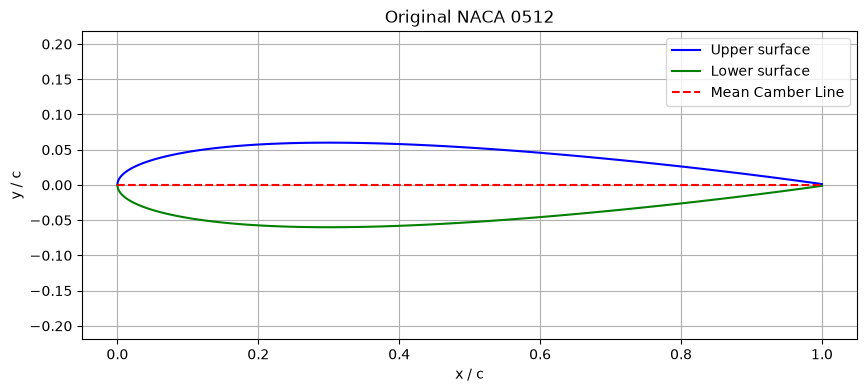

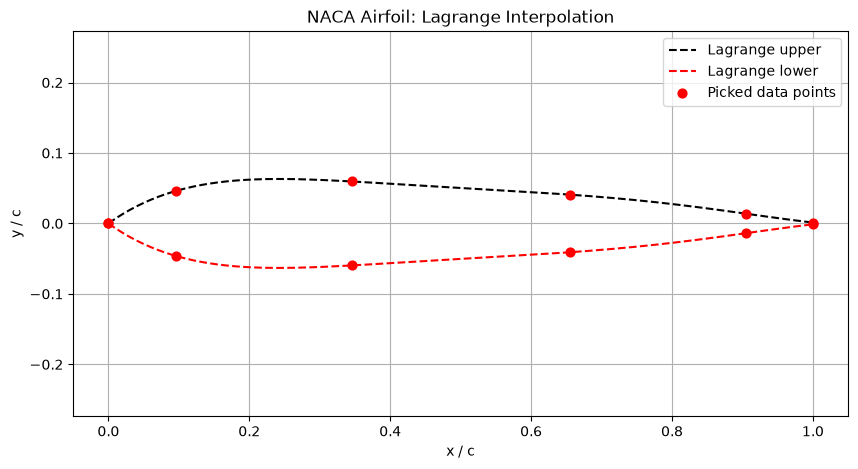

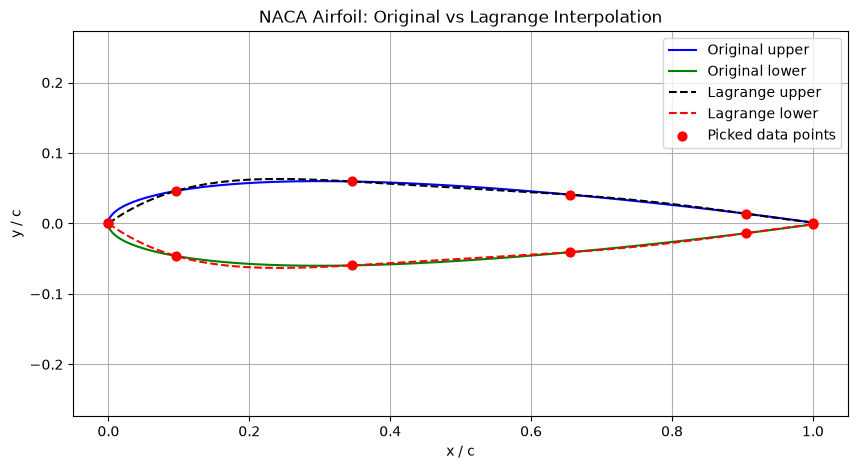

[0.        0.0954915 0.3454915 0.6545085 0.9045085 1.       ]
[0.         0.04604893 0.05957472 0.04091741 0.01391432 0.00126   ]
[0.        0.0954915 0.3454915 0.6545085 0.9045085 1.       ]
[ 0.         -0.04604893 -0.05957472 -0.04091741 -0.01391432 -0.00126   ]
NACA Airfoil: 0512

UPPER SURFACE
Maximum absolute error: 0.010509861663057946
RMS error: 0.0029532032298527555

LOWER SURFACE
Maximum absolute error: 0.010509861663057946
RMS error: 0.0029532032298527555

COMBINED AIRFOIL
Maximum absolute error: 0.010509861663057946
RMS error: 0.0029532032298527555


In [1]:
# random number generator for NACA 4-digit airfoil
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()

m = rng.choice([0.00, 0.01, 0.02, 0.03, 0.04])
p = rng.choice([0.2, 0.3, 0.4, 0.5])
t = rng.choice([0.08, 0.10, 0.12, 0.15])

M = int(round(m * 100))
P = int(round(p * 10))
T = int(round(t * 100))


print("NACA airfoil: NACA {}{}{:02d}".format(M, P, T))
print("Maximum camber  c =", m)
print("Location of maximum camber x =", p)
print("Maximum thickness ratio t =", t)
  

       #########################################################################

# Original NACA airfoil plotting

# Chordwise locations
N = 101
beta = np.linspace(0, np.pi, N)
x = (1 - np.cos(beta)) / 2

# Thickness distribution
yt = 5 * t * (
    0.2969 * np.sqrt(x)
    - 0.1260 * x
    - 0.3516 * x**2
    + 0.2843 * x**3
    - 0.1015 * x**4)


# Mean camber line and its slope
yc = np.zeros(N)
dyc = np.zeros(N)

for i in range(N):
    if x[i] <= p:
        yc[i] = (m / p**2) * (2*p*x[i] - x[i]**2)
        dyc[i] = (2*m / p**2) * (p - x[i])
    else:
        yc[i] = (m / (1-p)**2) * (
            (1 - 2*p) + 2*p*x[i] - x[i]**2)
        dyc[i] = (2*m / (1-p)**2) * (p - x[i])

theta = np.arctan(dyc)

xu = x - yt * np.sin(theta)
yu = yc + yt * np.cos(theta)

xl = x + yt * np.sin(theta)
yl = yc - yt * np.cos(theta)


plt.figure(figsize=(10, 4))

plt.plot(xu, yu, label="Upper surface", color="blue")
plt.plot(xl, yl, label="Lower surface", color="green")
plt.plot(x, yc, "--", label="Mean Camber Line", color="red")

plt.xlabel("x / c")
plt.ylabel("y / c")
plt.title("Original NACA {}{}{:02d}".format(M, P, T))
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


        #########################################################################


# Select six points from each surface
N_points = 6
indices = np.linspace(0, N-1, N_points, dtype=int)

x_upper = xu[indices]
y_upper = yu[indices]

x_lower = xl[indices]
y_lower = yl[indices]

          
#########################################################################################

# Lagrange interpolation

def Lagrng(x,y,xx):
    n = len(x)
    r = 0
    for i in range(n):
         s = y[i]
         for j in range(n):
             if i != j:
                 s = s*((xx - x[j]) / (x[i] - x[j]))
         r = r + s
    return r

        
        ##########################################################################


# Plotting the reconstructed airfoil
xx = np.linspace(0, 1, 300)

yu_lag = np.array([Lagrng(x_upper, y_upper, z) for z in xx])
yl_lag = np.array([Lagrng(x_lower, y_lower, z) for z in xx])


plt.figure(figsize=(10, 5))

plt.plot(xx, yu_lag, "--", label="Lagrange upper", color="black")
plt.plot(xx, yl_lag, "--", label="Lagrange lower", color="red")

plt.scatter(x_upper, y_upper, color="red", s=40, label="Picked data points", zorder=3)
plt.scatter(x_lower, y_lower, color="red", s=40, zorder=3)

plt.xlabel("x / c")
plt.ylabel("y / c")
plt.title("NACA Airfoil: Lagrange Interpolation")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


      ##########################################################################


# Plotting the original and reconstructed airfoil
plt.figure(figsize=(10, 5))

plt.plot(xu, yu, label="Original upper", color="blue")
plt.plot(xl, yl, label="Original lower", color="green")

plt.plot(xx, yu_lag, "--", label="Lagrange upper", color="black")
plt.plot(xx, yl_lag, "--", label="Lagrange lower", color="red")

plt.scatter(x_upper, y_upper, color="red", s=40, label="Picked data points", zorder=3)
plt.scatter(x_lower, y_lower, color="red", s=40, zorder=3)

plt.xlabel("x / c")
plt.ylabel("y / c")
plt.title("NACA Airfoil: Original vs Lagrange Interpolation")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

    ##########################################################################


print(x_upper)
print(y_upper)
print(x_lower)
print(y_lower)

# Error calculation
yu_original = np.interp(xx, xu, yu)
yl_original = np.interp(xx, xl, yl)

error_upper = yu_original - yu_lag
error_lower = yl_original - yl_lag

max_error_upper = np.max(np.abs(error_upper))
max_error_lower = np.max(np.abs(error_lower))

rms_upper = np.sqrt(np.mean(error_upper**2))
rms_lower = np.sqrt(np.mean(error_lower**2))

all_errors = np.concatenate((error_upper, error_lower))

max_error_combined = np.max(np.abs(all_errors))
rms_combined = np.sqrt(np.mean(all_errors**2))

print("NACA Airfoil: {}{}{:02d}".format(M, P, T))

print("\nUPPER SURFACE")
print("Maximum absolute error:", max_error_upper)
print("RMS error:", rms_upper)

print("\nLOWER SURFACE")
print("Maximum absolute error:", max_error_lower)
print("RMS error:", rms_lower)

print("\nCOMBINED AIRFOIL")
print("Maximum absolute error:", max_error_combined)
print("RMS error:", rms_combined)

NACA airfoil: NACA 1515
Maximum camber  c = 0.01
Location of maximum camber x = 0.5
Maximum thickness ratio t = 0.15


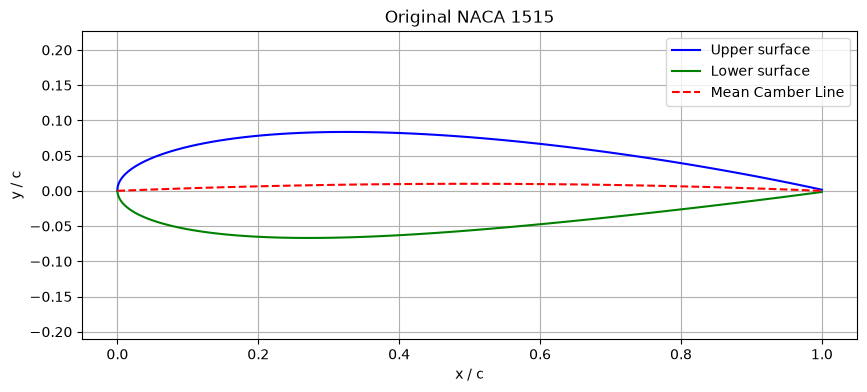

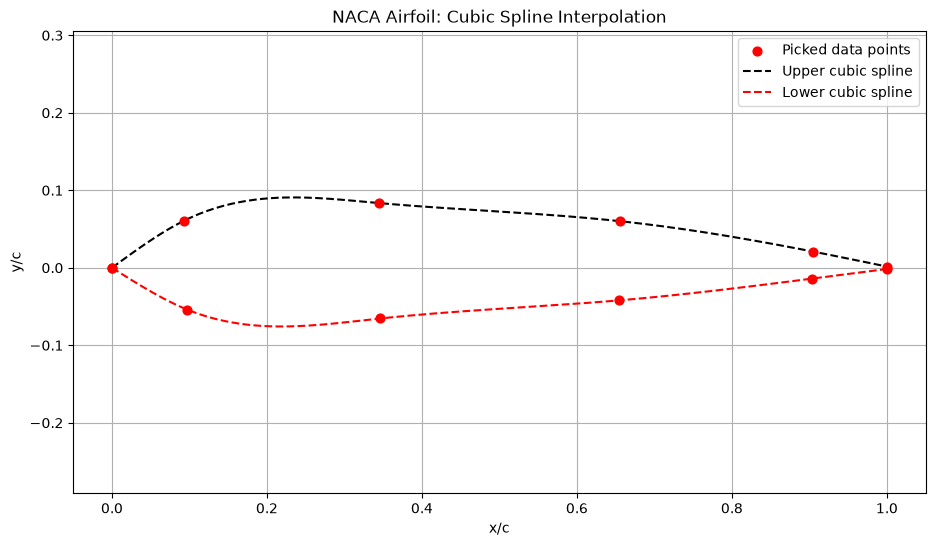

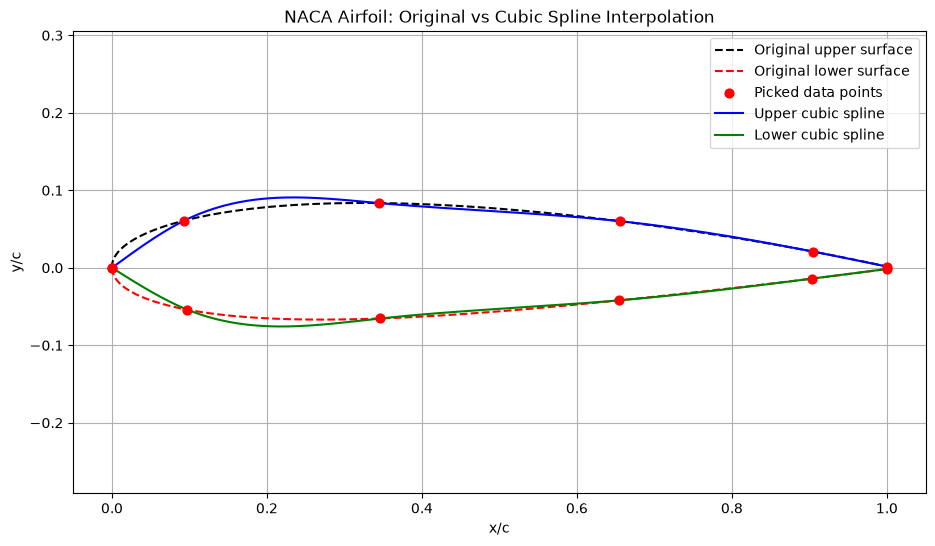

[0.         0.09362976 0.34457109 0.65514066 0.90507105 1.00006295]
[0.         0.06098597 0.08350779 0.06018794 0.02083872 0.00157374]
[0.         0.09735325 0.34641191 0.65387634 0.90394595 0.99993705]
[ 0.         -0.05407614 -0.06541762 -0.04209777 -0.01392889 -0.00157374]
NACA Airfoil: 1515

UPPER SURFACE
Maximum absolute error: 0.0165150404568833
RMS error: 0.00550324868954300

LOWER SURFACE
Maximum absolute error: 0.0154037176592633
RMS error: 0.00506585346359077

COMBINED AIRFOIL
Maximum absolute error: 0.0165150404568833
RMS error: 0.00528907446787863


In [2]:
# random number generator for NACA 4-digit airfoil
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()

m = rng.choice([0.00, 0.01, 0.02, 0.03, 0.04])
p = rng.choice([0.2, 0.3, 0.4, 0.5])
t = rng.choice([0.08, 0.10, 0.12, 0.15])

M = int(round(m * 100))
P = int(round(p * 10))
T = int(round(t * 100))


print("NACA airfoil: NACA {}{}{:02d}".format(M, P, T))
print("Maximum camber  c =", m)
print("Location of maximum camber x =", p)
print("Maximum thickness ratio t =", t)


       #########################################################################

# Original NACA airfoil plotting

# Chordwise locations
N = 101
beta = np.linspace(0, np.pi, N)
x = (1 - np.cos(beta)) / 2

# Thickness distribution
yt = 5 * t * (
    0.2969 * np.sqrt(x)
    - 0.1260 * x
    - 0.3516 * x**2
    + 0.2843 * x**3
    - 0.1015 * x**4)


# Mean camber line and its slope
yc = np.zeros(N)
dyc = np.zeros(N)

for i in range(N):
    if x[i] <= p:
        yc[i] = (m / p**2) * (2*p*x[i] - x[i]**2)
        dyc[i] = (2*m / p**2) * (p - x[i])
    else:
        yc[i] = (m / (1-p)**2) * (
            (1 - 2*p) + 2*p*x[i] - x[i]**2)
        dyc[i] = (2*m / (1-p)**2) * (p - x[i])

theta = np.arctan(dyc)

xu = x - yt * np.sin(theta)
yu = yc + yt * np.cos(theta)

xl = x + yt * np.sin(theta)
yl = yc - yt * np.cos(theta)


plt.figure(figsize=(10, 4))

plt.plot(xu, yu, label="Upper surface", color="blue")
plt.plot(xl, yl, label="Lower surface", color="green")
plt.plot(x, yc, "--", label="Mean Camber Line", color="red")

plt.xlabel("x / c")
plt.ylabel("y / c")
plt.title("Original NACA {}{}{:02d}".format(M, P, T))
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


      #########################################################################

# Select six points from each surface
N_points = 6
indices = np.linspace(0, N-1, N_points, dtype=int)

x_upper = xu[indices]
y_upper = yu[indices]

x_lower = xl[indices]
y_lower = yl[indices]

# Sorting because x range must be in increasing order
order_upper = np.argsort(x_upper)
x_upper = x_upper[order_upper]
y_upper = y_upper[order_upper]

order_lower = np.argsort(x_lower)
x_lower = x_lower[order_lower]
y_lower = y_lower[order_lower]



#########################################################################################

# Cubic Spline Interpolation

def spline_2nd_derivatives(x, y):
    
    n = len(x)

    if n < 3:
        raise ValueError("At least three data points are required.")

    if np.any(np.diff(x) <= 0):
        raise ValueError("The x values must be strictly increasing.")

    h = np.diff(x)

    A = np.zeros((n - 2, n - 2))
    b = np.zeros(n - 2) 

    for i in range(1, n - 1):
         row = i - 1

         b[row] = 6 * ((y[i + 1] - y[i]) / h[i]- (y[i] - y[i - 1]) / h[i - 1])
         A[row, row] = 2 * (h[i - 1] + h[i])
         if i > 1:
             A[row, row - 1] = h[i - 1]
         if i < n - 2:
             A[row, row + 1] = h[i]

    M_inner = np.linalg.solve(A, b)
    M = np.zeros(n)
    M[1:-1] = M_inner

    return h, M
   


h_upper, M_upper = spline_2nd_derivatives(x_upper, y_upper)
h_lower, M_lower = spline_2nd_derivatives(x_lower, y_lower)



def cubic_spline_value(x, y, h, M, xq):

    if xq < x[0] or xq > x[-1]:
        raise ValueError("Query point is outside the data range")

    i = np.searchsorted(x, xq) - 1 
    i = max(0, min(i, len(x) - 2)) # Restrict to a valid interval

    S = (M[i] * (x[i + 1] - xq)**3 / (6 * h[i])
        + M[i + 1] * (xq - x[i])**3 / (6 * h[i])
        + (y[i] - M[i] * h[i]**2 / 6)
        * (x[i + 1] - xq) / h[i]
        + (y[i + 1] - M[i + 1] * h[i]**2 / 6)
        * (xq - x[i]) / h[i])

    return S


x_plot_upper = np.linspace(x_upper[0], x_upper[-1], 300)
x_plot_lower = np.linspace(x_lower[0], x_lower[-1], 300)

y_plot_upper = np.array([
    cubic_spline_value(x_upper, y_upper, h_upper, M_upper, xq)for xq in x_plot_upper])

y_plot_lower = np.array([
    cubic_spline_value(x_lower, y_lower, h_lower, M_lower, xq)for xq in x_plot_lower])


        ########################################################################

# Plotting the reconstructed airfoil
plt.figure(figsize=(11, 6))

plt.scatter(x_upper, y_upper, color="red", s=40,label="Picked data points", zorder=3)
plt.scatter(x_lower, y_lower, color="red", s=40, zorder=3)

plt.plot(x_plot_upper, y_plot_upper, "--", color="black",label="Upper cubic spline")
plt.plot(x_plot_lower, y_plot_lower, "--", color="red",label="Lower cubic spline")

plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title("NACA Airfoil: Cubic Spline Interpolation")
plt.axis("equal")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


        ########################################################################


# Plotting the original and reconstructed airfoil
plt.figure(figsize=(11, 6))

plt.plot(xu, yu, "--", color="black", label="Original upper surface")
plt.plot(xl, yl, "--", color="red", label="Original lower surface")

plt.scatter(x_upper, y_upper, color="red", s=40,label="Picked data points", zorder=3)
plt.scatter(x_lower, y_lower, color="red", s=40, zorder=3)

plt.plot(x_plot_upper, y_plot_upper, color="blue",label="Upper cubic spline")
plt.plot(x_plot_lower, y_plot_lower, color="green",label="Lower cubic spline")

plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title("NACA Airfoil: Original vs Cubic Spline Interpolation")
plt.axis("equal")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


       ########################################################################

print(x_upper)
print(y_upper)
print(x_lower)
print(y_lower)

# Error calculation
x_eval_upper = np.linspace(x_upper[0], x_upper[-1], 300)
x_eval_lower = np.linspace(x_lower[0], x_lower[-1], 300)

y_reference_upper = np.interp(x_eval_upper,np.sort(xu),yu[np.argsort(xu)])
y_reference_lower = np.interp(x_eval_lower,np.sort(xl),yl[np.argsort(xl)])

y_spline_upper = np.array([
    cubic_spline_value(x_upper, y_upper, h_upper, M_upper, xq)for xq in x_eval_upper])

y_spline_lower = np.array([
    cubic_spline_value(x_lower, y_lower, h_lower, M_lower, xq)for xq in x_eval_lower])

error_upper = y_reference_upper - y_spline_upper
error_lower = y_reference_lower - y_spline_lower

max_error_upper = np.max(np.abs(error_upper))
max_error_lower = np.max(np.abs(error_lower))

rms_upper = np.sqrt(np.mean(error_upper**2))
rms_lower = np.sqrt(np.mean(error_lower**2))

all_errors = np.concatenate((error_upper, error_lower))

max_error_combined = np.max(np.abs(all_errors))
rms_combined = np.sqrt(np.mean(all_errors**2))

print("NACA Airfoil: {}{}{:02d}".format(M, P, T))

print("\nUPPER SURFACE")
print(f"Maximum absolute error: {max_error_upper:.16f}")
print(f"RMS error: {rms_upper:.17f}")

print("\nLOWER SURFACE")
print(f"Maximum absolute error: {max_error_lower:.16f}")
print(f"RMS error: {rms_lower:.17f}")

print("\nCOMBINED AIRFOIL")
print(f"Maximum absolute error: {max_error_combined:.16f}")
print(f"RMS error: {rms_combined:.17f}")